# Otros modelos y clusters de países 

En el notebook 02 replicamos a **Ferreira y Gignoux (2014)**: la IOp es el R² de una regresión **MCO**. 

## 1. Librerías

In [ ]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import KFold, GridSearchCV, train_test_split
from sklearn.linear_model import LinearRegression, LassoCV, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth
from sklearn.metrics import (silhouette_score, adjusted_rand_score, roc_auc_score,
                             balanced_accuracy_score, confusion_matrix)

## 2. Rutas y constantes 

In [2]:
CARPETA_PISA = Path.cwd()
if not (CARPETA_PISA / "datos").exists():
    CARPETA_PISA = CARPETA_PISA.parent          # si el notebook está en /scripts
DATOS = CARPETA_PISA / "datos"
SALIDA = DATOS / "resultados"
SALIDA.mkdir(exist_ok=True)

LATAM = ["ARG", "BRA", "CHL", "COL", "CRI", "DOM", "ECU",
         "GTM", "MEX", "PER", "PRY", "SLV", "URY"]
PV   = [f"PV{i}MATH" for i in range(1, 11)]
PESO = "W_FSTUWT"

SEMILLA = 42                                    # para que todo sea reproducible
AZUL, GRIS, TINTA, TENUE = "#2a78d6", "#b5b3ad", "#0b0b0b", "#898781"

## 3. La base: circunstancias + puntajes + peso (grupos y familias)

Si `base_ml.parquet` ya existe, se lee directo. Si no, se construye con **el mismo código de la sección 5 del notebook 02** y se guarda.

In [3]:
BASE = SALIDA / "base_ml.parquet"

if BASE.exists():
    base = pd.read_parquet(BASE)
    print("Leída la base guardada.")
else:
    inicio = time.time()
    CIRC = ["MALE", "P1ISCED", "P2ISCED", "OCOP1", "ST022Q01TA", "IMMIG", "ST255Q01JA",
            "ST250Q02JA", "ST250Q04JA", "ST250Q05JA", "ST254Q01JA", "ST251Q01JA",
            "ST251Q06JA", "ST251Q07JA"]
    est = pd.read_parquet(DATOS / "estudiantes", columns=["CNT", "CNTSCHID", "OECD"] + CIRC + PV + [PESO])
    est["CNT"] = est["CNT"].astype(str)
    esc = pd.read_parquet(DATOS / "escuelas", columns=["CNT", "CNTSCHID", "SC001Q01TA"])
    esc["CNT"] = esc["CNT"].astype(str)
    est = est.merge(esc, on=["CNT", "CNTSCHID"], how="left")
    est = est[est[PV].notna().all(axis=1) & est[PESO].notna()].reset_index(drop=True)

    # ---- mismo código del notebook 02, sección 5 ----
    def educ_padre(x):
        # ISCED de PISA: 1-2 = hasta básica · 3-4 = bachillerato · 5-6 = post-sec./técnico · 7-9 = universitaria
        return pd.Series(np.select([x <= 2, x <= 4, x <= 6, x <= 9],
                                   ["1 ≤ básica", "2 bachillerato", "3 post-sec./técnico", "4 universitaria"],
                                   "faltante"), index=x.index)


    def ocupacion(x):
        # OCOP1 es texto (código ISCO). Primer dígito: 1-3 alta, 4-5 y 0 (FF.AA.) media, 6-9 manual.
        # "97" = códigos auxiliares PISA (hogar, desempleo…). "995"-"999" = no respuesta.
        x = x.astype(str).str.strip()
        d = x.str[0]
        return pd.Series(np.select(
            [x.str.len() >= 3, x == "97", d.isin(["1", "2", "3"]), d.isin(["4", "5", "0"]), d.isin(["6", "7", "8", "9"])],
            ["faltante", "4 no trabaja/otro", "1 alta calificación", "2 media", "3 manual/elemental"],
            "faltante"), index=x.index)


    def si_no(condicion_si, x):
        return pd.Series(np.select([x.isna(), condicion_si], ["faltante", "sí"], "no"), index=x.index)


    def libros(x):
        return pd.Series(np.select([x <= 2, x == 3, x == 4, x >= 5],
                                   ["1 0-10", "2 11-25", "3 26-100", "4 más de 100"], "faltante"), index=x.index)


    def zona(x):
        return pd.Series(np.select([x == 1, x <= 3, x <= 6], ["1 rural", "2 pueblo", "3 ciudad"], "faltante"),
                         index=x.index)


    c = pd.DataFrame(index=est.index)
    c["sexo"]        = si_no(est["MALE"] == 1, est["MALE"])                 # sí = hombre
    c["educ_p1"]     = educ_padre(est["P1ISCED"])
    c["educ_p2"]     = educ_padre(est["P2ISCED"])
    c["ocup_p1"]     = ocupacion(est["OCOP1"])
    c["idioma_otro"] = si_no(est["ST022Q01TA"] == 2, est["ST022Q01TA"])
    c["migrante"]    = si_no(est["IMMIG"].isin([2, 3]), est["IMMIG"])
    c["libros"]      = libros(est["ST255Q01JA"])
    c["computadora"] = si_no(est["ST250Q02JA"] == 1, est["ST250Q02JA"])
    c["celular"]     = si_no(est["ST250Q04JA"] == 1, est["ST250Q04JA"])
    c["internet"]    = si_no(est["ST250Q05JA"] == 1, est["ST250Q05JA"])
    c["tv"]          = si_no(est["ST254Q01JA"] >= 2, est["ST254Q01JA"])     # 2+ = al menos una
    c["auto"]        = si_no(est["ST251Q01JA"] >= 2, est["ST251Q01JA"])
    c["instrumento"] = si_no(est["ST251Q06JA"] >= 2, est["ST251Q06JA"])
    c["arte"]        = si_no(est["ST251Q07JA"] >= 2, est["ST251Q07JA"])
    c["zona"]        = zona(est["SC001Q01TA"])
    # -------------------------------------------------

    base = pd.concat([est[["CNT", "OECD"] + PV + [PESO]], c], axis=1)
    base[PV + [PESO]] = base[PV + [PESO]].astype("float32")
    base.to_parquet(BASE, index=False)
    print(f"Base construida y guardada en {time.time() - inicio:.0f} s")

CIRCUNSTANCIAS = ["sexo", "educ_p1", "educ_p2", "ocup_p1", "idioma_otro", "migrante", "libros",
                  "computadora", "celular", "internet", "tv", "auto", "instrumento", "arte", "zona"]
print(f"{len(base):,} estudiantes · {base['CNT'].nunique()} países")

Base construida y guardada en 17 s
747,068 estudiantes · 89 países


Las circunstancias agrupadas...

In [4]:
GRUPOS = {                       # circunstancia del paper → columnas
    "Sexo":                  ["sexo"],
    "Educación padre/tutor 1": ["educ_p1"],
    "Educación padre/tutor 2": ["educ_p2"],
    "Ocupación padre/tutor 1": ["ocup_p1"],
    "Idioma en casa":        ["idioma_otro"],
    "Migración":             ["migrante"],
    "Libros en casa":        ["libros"],
    "Bienes del hogar":      ["computadora", "celular", "internet", "tv", "auto"],
    "Posesiones culturales": ["instrumento", "arte"],
    "Zona de la escuela":    ["zona"],
}

FAMILIAS = {                     # para el gráfico: 5 familias
    "Padres (educación y ocupación)": ["Educación padre/tutor 1", "Educación padre/tutor 2", "Ocupación padre/tutor 1"],
    "Recursos del hogar (libros, bienes, cultura)": ["Libros en casa", "Bienes del hogar", "Posesiones culturales"],
    "Zona de la escuela": ["Zona de la escuela"],
    "Migración e idioma": ["Migración", "Idioma en casa"],
    "Sexo": ["Sexo"],
}

### La matriz de cada país (dummies)

In [15]:
def dummies(d):
    # Una columna 0/1 por categoría. Referencia de cada variable = su primera categoría real
    # ("no", "1 rural", "1 0-10"…), nunca "faltante", para que los coeficientes se lean fácil.
    X = pd.get_dummies(d[CIRCUNSTANCIAS], prefix_sep="_", dtype="float32")
    referencias = []
    for v in CIRCUNSTANCIAS:
        reales = sorted(k for k in d[v].unique() if k != "faltante")
        if reales:                                   # si la variable existe en el país
            referencias.append(f"{v}_{reales[0]}")
        # si es 100 % faltante, su única columna no varía y se elimina después
    return X.drop(columns=[r for r in referencias if r in X.columns])


def datos_pais(pais):
    d = base[base["CNT"] == pais]
    X = dummies(d)
    X = X.loc[:, X.std() > 0]
    Y = d[PV].to_numpy("float64")
    w = d[PESO].to_numpy("float64")
    w = w / w.mean()
    return X, Y, w


X, Y, w = datos_pais("ECU")
print(f"Ecuador: {X.shape[0]:,} estudiantes × {X.shape[1]} columnas")

Ecuador: 9,128 estudiantes × 37 columnas


---
# A. IOp con otros modelos...

## A1. Entrenar - probar

1. **Entrenar** un modelo que prediga el puntaje con las circunstancias, usando una parte de los estudiantes.
2. **Probar** el modelo en estudiantes que **no vio** (fuera de muestra).
3. La IOp es el **R² fuera de muestra**: qué parte de la desigualdad podemos predecir **de verdad** con el origen.

**Validación cruzada (5 *folds*):** partimos a los estudiantes en 5 grupos. Entrenamos con 4 y predecimos el 5.º; repetimos 5 veces. Así **cada estudiante recibe una predicción hecha sin verlo**.

In [16]:
def r2_w(y, yhat, w):
    # R² ponderado
    ybar = np.average(y, weights=w)
    return 1 - np.sum(w * (y - yhat) ** 2) / np.sum(w * (y - ybar) ** 2)


def iop_cv(modelo, X, y, w, k=5):
    # R² fuera de muestra con validación cruzada de k folds (con pesos)
    X = np.asarray(X)
    pred = np.empty_like(y)
    for entreno, prueba in KFold(k, shuffle=True, random_state=SEMILLA).split(X):
        m = clone(modelo)
        m.fit(X[entreno], y[entreno], sample_weight=w[entreno])
        pred[prueba] = m.predict(X[prueba])
    return r2_w(y, pred, w)

## A2. Primero, ver el sobreajuste con un árbol (ejemplo...)

Un **árbol de decisión** parte a los estudiantes en grupos según sus circunstancias ("¿padres universitarios? → ¿tiene computadora? → …"). Cada hoja es un **tipo** de estudiante, como en la teoría de Roemer.

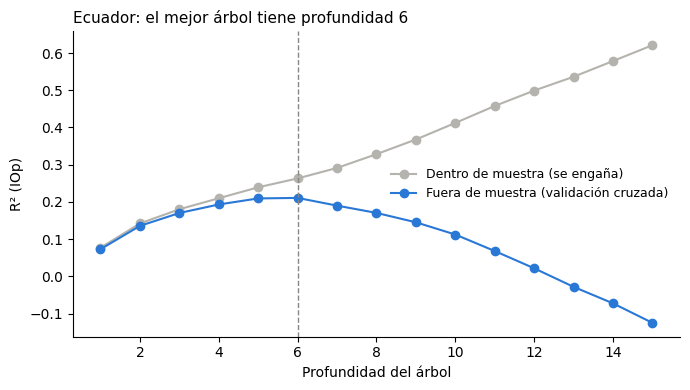

In [17]:
y1 = Y[:, 0]
profundidades = range(1, 16)
dentro, fuera = [], []
for p in profundidades:
    arbol = DecisionTreeRegressor(max_depth=p, random_state=SEMILLA)
    arbol.fit(X, y1, sample_weight=w)
    dentro.append(r2_w(y1, arbol.predict(X), w))
    fuera.append(iop_cv(arbol, X, y1, w))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(profundidades, dentro, marker="o", color=GRIS, label="Dentro de muestra (se engaña)")
ax.plot(profundidades, fuera, marker="o", color=AZUL, label="Fuera de muestra (validación cruzada)")
mejor = profundidades[int(np.argmax(fuera))]
ax.axvline(mejor, color=TENUE, ls="--", lw=1)
ax.set_xlabel("Profundidad del árbol")
ax.set_ylabel("R² (IOp)")
ax.set_title(f"Ecuador: el mejor árbol tiene profundidad {mejor}", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## A3. Los modelos a utilizar

| Modelo | Qué hace | Por qué lo incluimos |
| --- | --- | --- |
| **MCO** | Regresión lineal (la del paper) | Punto de referencia |
| **Lasso** | Regresión lineal que "apaga" las variables que no ayudan | Controla el sobreajuste de la MCO |
| **Árbol** | Parte a los estudiantes en tipos | Capta interacciones; fácil de interpretar |
| **Bosque aleatorio** | Promedio de cientos de árboles distintos | Más estable que un solo árbol (Brunori et al., 2023) |
| **Gradient boosting** | Árboles pequeños en cadena, cada uno corrige al anterior | Suele ser el más preciso |

Los **hiperparámetros** (por ejemplo, la profundidad del árbol) se eligen con validación cruzada **dentro** del entrenamiento (`GridSearchCV`, `LassoCV`).

In [18]:
MODELOS = {
    "MCO": LinearRegression(),
    "Lasso": LassoCV(cv=3, random_state=SEMILLA),
    "Árbol": GridSearchCV(DecisionTreeRegressor(min_samples_leaf=30, random_state=SEMILLA),
                          {"max_depth": [2, 3, 4, 5, 6, 8]}, cv=3),
    "Bosque aleatorio": RandomForestRegressor(n_estimators=150, min_samples_leaf=30, max_features=0.33,
                                              max_samples=0.5, n_jobs=-1, random_state=SEMILLA),
    "Gradient boosting": HistGradientBoostingRegressor(learning_rate=0.05, max_iter=250, max_leaf_nodes=15,
                                                       min_samples_leaf=40, early_stopping=False,
                                                       random_state=SEMILLA),
}


def comparar_modelos(pais, n_pv=10):
    # IOp fuera de muestra de cada modelo, para los n_pv valores plausibles
    X, Y, w = datos_pais(pais)
    res = {nombre: [iop_cv(m, X, Y[:, i], w) for i in range(n_pv)] for nombre, m in MODELOS.items()}
    res = pd.DataFrame(res)                             # filas = PV, columnas = modelos
    return res.mean(), res.std()                        # promedio y variación entre PV

## A4. Ecuador: ¿cuánto cambia la IOp según el modelo?

Corremos los 5 modelos con los **10 PV** (se promedian, como manda PISA). Agregamos la IOp MCO **dentro de muestra** del paper para comparar.

In [19]:
mco_02 = pd.read_csv(SALIDA / "paso3_iop_mco_por_pais.csv", index_col="pais")

inicio = time.time()
media_ecu, de_ecu = comparar_modelos("ECU")
print(f"Listo en {time.time() - inicio:.0f} s\n")

tabla_ecu = pd.DataFrame({"IOp": media_ecu, "variación entre PV": de_ecu})
tabla_ecu.loc["MCO dentro de muestra (notebook 02)"] = [mco_02.loc["ECU", "iop"], np.nan]
tabla_ecu.round(3)

Listo en 103 s



,IOp,variación entre PV
MCO,0.256,0.005
Lasso,0.256,0.005
Árbol,0.211,0.008
Bosque aleatorio,0.246,0.005
Gradient boosting,0.273,0.007
MCO dentro de muestra (notebook 02),0.265,NaN


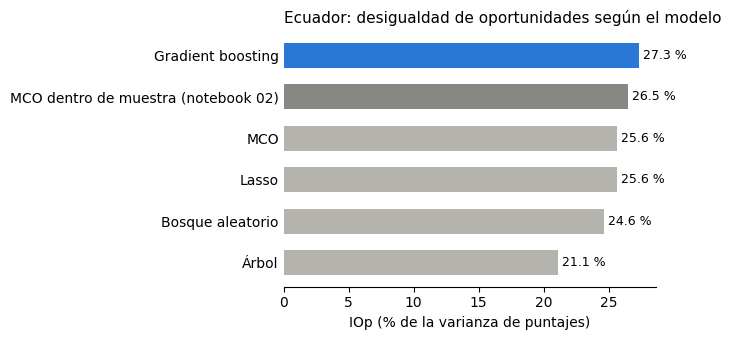

In [20]:
d = tabla_ecu["IOp"].sort_values()
colores = [AZUL if i == d.idxmax() else (TENUE if "02" in i else GRIS) for i in d.index]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(d.index, 100 * d, color=colores, height=0.6)
for i, v in enumerate(d):
    ax.text(100 * v + 0.3, i, f"{100 * v:.1f} %", va="center", fontsize=9)
ax.set_xlabel("IOp (% de la varianza de puntajes)")
ax.set_title("Ecuador: desigualdad de oportunidades según el modelo", loc="left", fontsize=11)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

## A5. Toda América Latina

Repetimos la comparación para los 13 países.

In [23]:
N_PV = 10

filas = []
inicio = time.time()
for pais in [p for p in LATAM if p in base["CNT"].unique()]:
    t = time.time()
    m, s = comparar_modelos(pais, N_PV)
    fila = {"pais": pais, **m.add_prefix("iop_").to_dict(), **s.add_prefix("varpv_").to_dict()}
    filas.append(fila)
    print(f"{pais}: {time.time() - t:.0f} s")

ml = pd.DataFrame(filas).set_index("pais")
ml["iop_mco_dentro"] = mco_02["iop"]
ml["mejor_modelo"] = ml[[f"iop_{n}" for n in MODELOS]].idxmax(axis=1).str.replace("iop_", "")
ml["iop_ml"] = ml[[f"iop_{n}" for n in MODELOS]].max(axis=1)
ml["incompleto"] = mco_02["incompleto"]
print(f"\nTotal: {(time.time() - inicio) / 60:.1f} min")
ml[["iop_mco_dentro", "iop_MCO", "iop_ml", "mejor_modelo", "incompleto"]].sort_values("iop_ml", ascending=False).round(3)

ARG: 128 s
BRA: 312 s
CHL: 97 s
COL: 90 s
CRI: 98 s
DOM: 126 s
ECU: 131 s
GTM: 111 s
MEX: 119 s
PER: 106 s
PRY: 108 s
SLV: 84 s
URY: 105 s

Total: 26.9 min


,iop_mco_dentro,iop_MCO,iop_ml,mejor_modelo,incompleto
pais,,,,,
BRA,0.377,0.373,0.391,Gradient boosting,False
GTM,0.374,0.363,0.387,Gradient boosting,False
COL,0.345,0.333,0.347,Gradient boosting,False
PRY,0.341,0.331,0.347,Gradient boosting,False
ARG,0.317,0.305,0.332,Gradient boosting,False
DOM,0.273,0.262,0.305,Gradient boosting,False
PER,0.285,0.275,0.288,Gradient boosting,False
URY,0.294,0.284,0.284,Lasso,False
ECU,0.265,0.256,0.273,Gradient boosting,False


### Gráfico: MCO del paper vs. otros modelos

Para cada país: **gris** = IOp MCO dentro de muestra (notebook 02, método del paper); **azul** = mejor modelo fuera de muestra. La línea une los dos: si el punto azul está a la derecha, el método clásico **subestimaba** la desigualdad de oportunidades.

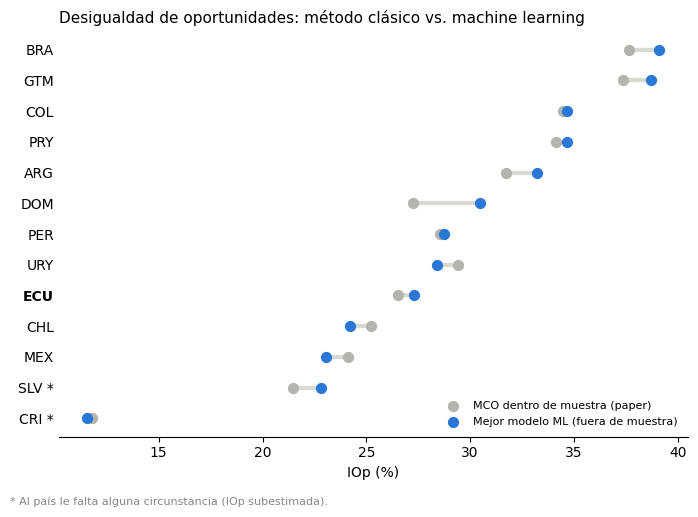

Guardado: c:\Users\pauls\Desktop\Yachay\Pisa\datos\resultados\paso4_iop_ml_latam.csv


In [24]:
d = ml.sort_values("iop_ml")
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(7, 5))
ax.hlines(y, 100 * d["iop_mco_dentro"], 100 * d["iop_ml"], color="#d9d8d3", lw=3)
ax.scatter(100 * d["iop_mco_dentro"], y, color=GRIS, s=50, zorder=3, label="MCO dentro de muestra (paper)")
ax.scatter(100 * d["iop_ml"], y, color=AZUL, s=50, zorder=3, label="Mejor modelo ML (fuera de muestra)")
etiquetas = [p + (" *" if inc else "") for p, inc in zip(d.index, d["incompleto"])]
ax.set_yticks(y, etiquetas)
for t in ax.get_yticklabels():
    t.set_fontweight("bold" if t.get_text().startswith("ECU") else "normal")
ax.set_xlabel("IOp (%)")
ax.set_title("Desigualdad de oportunidades: método clásico vs. machine learning", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.figtext(0.01, -0.02, "* Al país le falta alguna circunstancia (IOp subestimada).", fontsize=8, color=TENUE)
plt.tight_layout()
plt.show()

ml.to_csv(SALIDA / "paso4_iop_ml_latam.csv")
print("Guardado:", SALIDA / "paso4_iop_ml_latam.csv")

---
# B. Clusters de países

**Pregunta:** ¿hay "familias" de países con perfiles parecidos de **nivel** (puntaje medio), **desigualdad total** (DE) e **injusticia** (IOp)? ¿En qué familia cae Ecuador?

Usamos la tabla del notebook 02 (89 países). Dejamos fuera a los países **incompletos** (su IOp está subestimada y los agruparía mal).

In [38]:
paises = mco_02[~mco_02["incompleto"]].copy()
VARS = ["media", "de", "iop"]
print(f"{len(paises)} países para agrupar")
paises[VARS].describe().round(2)

76 países para agrupar


,media,de,iop
count,76.00,76.00,76.00
mean,422.38,84.85,0.28
std,55.59,14.63,0.06
min,311.65,55.48,0.13
25%,379.13,74.70,0.25
50%,418.88,87.32,0.28
75%,464.08,95.70,0.32
max,562.90,112.07,0.50


## B1. Estandarizar

Las variables tienen escalas muy distintas: la media está en cientos de puntos y la IOp entre 0 y 1. Si no las igualamos, K-means solo "vería" la media. `StandardScaler` pasa cada variable a **media 0 y desviación 1** (puntajes z).

In [39]:
Z = StandardScaler().fit_transform(paises[VARS])

## B2. K-means: ¿cuántos grupos?

K-means necesita que le digamos **k** (el número de grupos).
- **Codo (inercia):** distancia total de cada país al centro de su grupo. Buscamos dónde deja de bajar mucho.
- **Silueta:** de −1 a 1. Mide si cada país está más cerca de su grupo que de los otros. **Más alto = grupos más claros.**

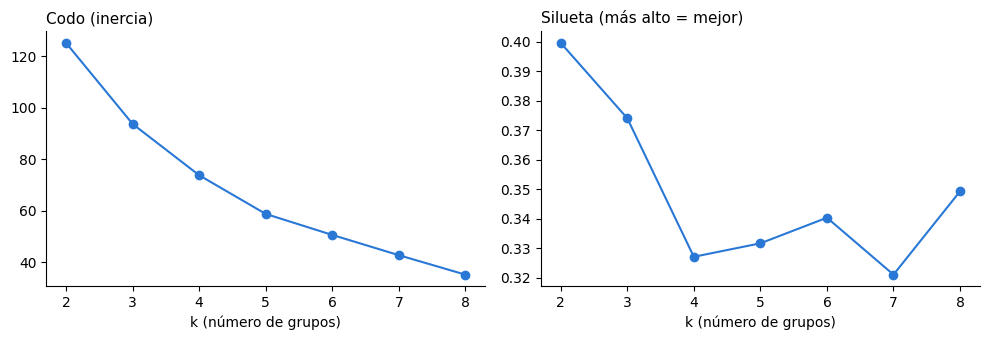

2    0.400
3    0.374
4    0.327
5    0.332
6    0.340
7    0.321
8    0.349

k con la mejor silueta: 2


In [27]:
ks = range(2, 9)
inercia, silueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(Z)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(Z, km.labels_))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5))
a1.plot(ks, inercia, marker="o", color=AZUL); a1.set_title("Codo (inercia)", loc="left", fontsize=11)
a2.plot(ks, silueta, marker="o", color=AZUL); a2.set_title("Silueta (más alto = mejor)", loc="left", fontsize=11)
for a in (a1, a2):
    a.set_xlabel("k (número de grupos)")
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(pd.Series(silueta, index=ks, name="silueta").round(3).to_string())
K = list(ks)[int(np.argmax(silueta))]
print(f"\nk con la mejor silueta: {K}")

In [45]:
K = 4     # ← fijamos k a mano, se ve que con k=5, los clusters no tienen mucho sentido
km = KMeans(n_clusters=K, n_init=20, random_state=SEMILLA).fit(Z)
paises["kmeans"] = km.labels_

perfil = paises.groupby("kmeans")[VARS].mean().round(2)
perfil["n_paises"] = paises["kmeans"].value_counts()
perfil["países"] = paises.groupby("kmeans").apply(lambda g: ", ".join(sorted(g.index)), include_groups=False)
print(f"Ecuador está en el grupo {paises.loc['ECU', 'kmeans']}")
perfil

Ecuador está en el grupo 0


,media,de,iop,n_paises,países
kmeans,,,,,
0,372.61,67.84,0.22,19,"ARM, CHL, DOM, ECU, IDN, JOR, KAZ, KEN, KGZ, K..."
1,446.75,98.76,0.35,13,"ARE, AUT, AZE, BEL, BGR, CHE, FRA, HUN, ISR, Q..."
2,370.57,76.95,0.34,15,"ARG, BRA, COL, GTM, LBN, MDA, MKD, MNG, MYS, P..."
3,470.87,93.85,0.26,29,"ALB, AUS, BRN, CZE, DNK, ESP, EST, FIN, GBR, G..."


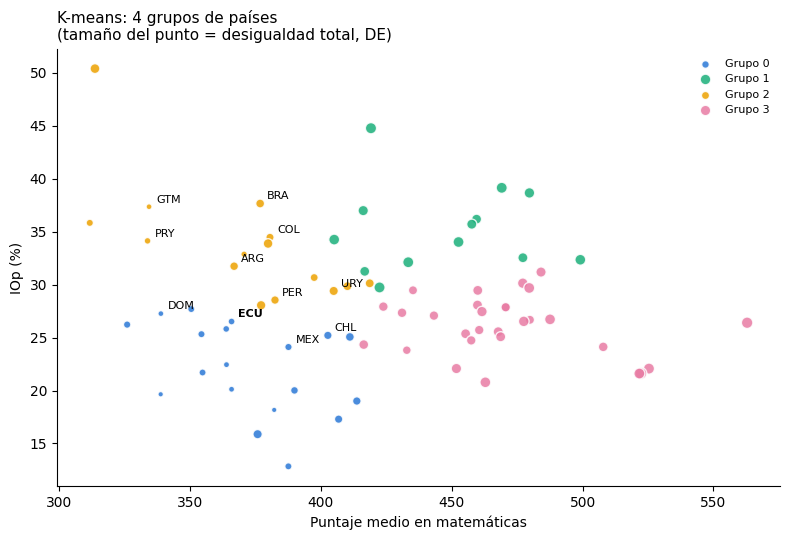

In [46]:
COLORES_GRUPO = ["#2a78d6", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7", "#e8613c", "#3fb8c4", "#8a8f2a"]

def dibujar_grupos(col, titulo):
    fig, ax = plt.subplots(figsize=(8, 5.5))
    for g, d in paises.groupby(col):
        ax.scatter(d["media"], 100 * d["iop"], s=d["de"] - 40, color=COLORES_GRUPO[g % 8],
                   alpha=0.85, label=f"Grupo {g}", edgecolor="white", zorder=3)
    for p, r in paises.iterrows():
        if p in LATAM:
            ax.annotate(p, (r["media"], 100 * r["iop"]), xytext=(5, 3), textcoords="offset points",
                        fontsize=8, fontweight="bold" if p == "ECU" else "normal")
    ax.set_xlabel("Puntaje medio en matemáticas")
    ax.set_ylabel("IOp (%)")
    ax.set_title(titulo + "\n(tamaño del punto = desigualdad total, DE)", loc="left", fontsize=11)
    ax.legend(frameon=False, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

dibujar_grupos("kmeans", f"K-means: {K} grupos de países")

## B3. Mean Shift: que los datos decidan cuántos grupos

Su único parámetro es el ancho de banda

In [48]:
ancho = estimate_bandwidth(Z, quantile=0.25, random_state=SEMILLA)
ms = MeanShift(bandwidth=ancho).fit(Z)
paises["meanshift"] = ms.labels_

print(f"Ancho de banda: {ancho:.2f} → Mean Shift encontró {paises['meanshift'].nunique()} grupos")
print(f"Ecuador está en el grupo {paises.loc['ECU', 'meanshift']}")

perfil_ms = paises.groupby("meanshift")[VARS].mean().round(2)
perfil_ms["n_paises"] = paises["meanshift"].value_counts()
perfil_ms["países"] = paises.groupby("meanshift").apply(lambda g: ", ".join(sorted(g.index)), include_groups=False)
perfil_ms

Ancho de banda: 1.43 → Mean Shift encontró 3 grupos
Ecuador está en el grupo 1


,media,de,iop,n_paises,países
meanshift,,,,,
0,455.56,93.76,0.29,47,"ALB, ARE, AUS, AUT, AZE, BEL, BGR, BRA, BRN, C..."
1,368.78,68.38,0.25,27,"ARG, ARM, CHL, COL, DOM, ECU, GTM, IDN, JOR, K..."
2,366.38,97.82,0.48,2,"ROU, ZMB"


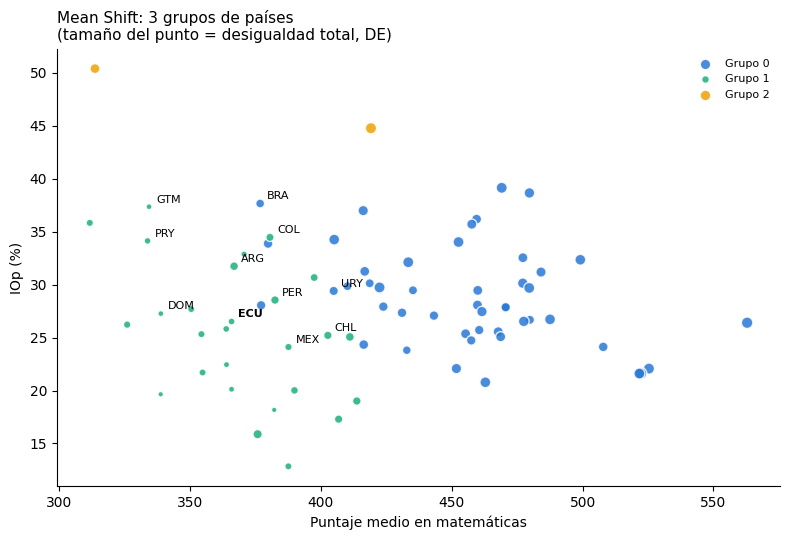

In [49]:
dibujar_grupos("meanshift", f"Mean Shift: {paises['meanshift'].nunique()} grupos de países")


## B4. Comparar K-means y Mean Shift

- **Tabla cruzada:** cuántos países de cada grupo de K-means caen en cada grupo de Mean Shift.
- **Índice de Rand ajustado (ARI):** 1 = los dos métodos agrupan igual; 0 = coinciden como al azar.

In [50]:
print(f"ARI = {adjusted_rand_score(paises['kmeans'], paises['meanshift']):.2f}")
pd.crosstab(paises["kmeans"], paises["meanshift"], rownames=["K-means"], colnames=["Mean Shift"])

ARI = 0.43


Mean Shift,0,1,2
K-means,,,
0,0,19,0
1,12,0,1
2,6,8,1
3,29,0,0


**Cómo leerlo:** si el ARI es alto, los grupos son **robustos**

In [51]:
pares_km = paises.index[paises["kmeans"] == paises.loc["ECU", "kmeans"]].tolist()
pares_ms = paises.index[paises["meanshift"] == paises.loc["ECU", "meanshift"]].tolist()
print("Pares de Ecuador (K-means):  ", ", ".join(pares_km))
print("Pares de Ecuador (Mean Shift):", ", ".join(pares_ms))

paises[VARS + ["kmeans", "meanshift"]].to_csv(SALIDA / "paso4_clusters_paises.csv")
print("Guardado:", SALIDA / "paso4_clusters_paises.csv")

Pares de Ecuador (K-means):   KSV, DOM, ECU, KEN, KGZ, PSE, CHL, MNE, MEX, IDN, MAR, KHM, SAU, QKI, KAZ, QTJ, THA, ARM, JOR
Pares de Ecuador (Mean Shift): GTM, RWA, COL, PRY, PHL, ARG, MYS, PER, KSV, DOM, ECU, KEN, KGZ, PSE, CHL, MNE, MEX, IDN, MAR, KHM, SAU, QKI, KAZ, QTJ, THA, ARM, JOR
Guardado: c:\Users\pauls\Desktop\Yachay\Pisa\datos\resultados\paso4_clusters_paises.csv


---
# C. Clasificación: ¿bajo el nivel 2? < 420,07

- **Bajo desempeño:** puntaje en matemáticas **menor a 420,07** (debajo del nivel 2, el mínimo que la OCDE considera como un "conocimiento básico").
- **Desempeño mínimo o más:** 420,07 o más.

**Pregunta:** ¿qué tan bien **predicen las circunstancias de origen** si un estudiante ecuatoriano quedará bajo el nivel 2? Es otra forma de ver la desigualdad de oportunidades: si el origen predice muy bien el fracaso, el sistema es poco justo.

In [52]:
CORTE_N2 = 420.07
bajo = (Y < CORTE_N2)                                   # 10 columnas: una por PV
print(f"Ecuador: {100 * np.average(bajo, axis=0, weights=w).mean():.1f} % de estudiantes bajo el nivel 2 (con pesos)")

Ecuador: 80.2 % de estudiantes bajo el nivel 2 (con pesos)


## C1. Entrenar y probar

- Separamos **70 % entrenamiento / 30 % prueba**, manteniendo la proporción de clases (`stratify`).
- Dos modelos: **regresión logística** (lineal, interpretable) y **bosque aleatorio** (capta interacciones).
- `class_weight="balanced"`: como la mayoría está bajo el nivel 2, le pedimos al modelo que no ignore a la clase más pequeña.
- Repetimos con los **10 PV** y promediamos.

In [53]:
CLASIFICADORES = {
    "Regresión logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Bosque aleatorio": RandomForestClassifier(n_estimators=200, min_samples_leaf=20, class_weight="balanced",
                                               n_jobs=-1, random_state=SEMILLA),
}

resultados = []
for i in range(10):
    Xe, Xp, ye, yp, we, wp = train_test_split(X.to_numpy(), bajo[:, i], w, test_size=0.3,
                                              stratify=bajo[:, i], random_state=SEMILLA)
    for nombre, modelo in CLASIFICADORES.items():
        m = clone(modelo).fit(Xe, ye, sample_weight=we)
        prob = m.predict_proba(Xp)[:, 1]
        resultados.append({"modelo": nombre, "pv": i + 1,
                           "AUC": roc_auc_score(yp, prob, sample_weight=wp),
                           "Exactitud balanceada": balanced_accuracy_score(yp, m.predict(Xp), sample_weight=wp)})
        if i == 0 and nombre == "Bosque aleatorio":
            matriz = confusion_matrix(yp, m.predict(Xp), sample_weight=wp, normalize="true")

pd.DataFrame(resultados).groupby("modelo")[["AUC", "Exactitud balanceada"]].agg(["mean", "std"]).round(3)

AUC        Exactitud balanceada       
                      mean    std                 mean    std
modelo                                                       
Bosque aleatorio     0.774  0.005                0.705  0.006
Regresión logística  0.778  0.006                0.707  0.010

**Entonces...** un AUC de 0,70, significa que con **solo saber el origen** del estudiante acertamos 7 de cada 10 veces quién está en mayor riesgo. El bosque no supera a la logística, las relaciones son casi lineales.

## C2. Matriz de confusión (bosque aleatorio, PV1)

Filas = la realidad; columnas = lo que predijo el modelo. Cada fila suma 100 %.

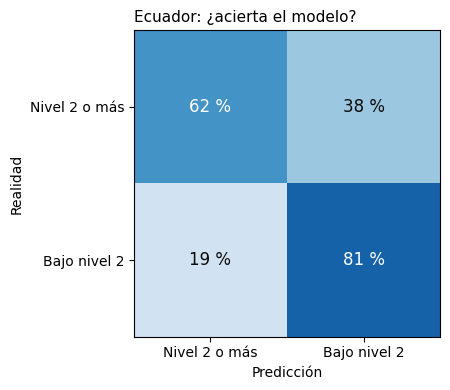

In [ ]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(matriz, cmap="Blues", vmin=0, vmax=1)
nombres = ["Nivel 2 o más", "Bajo nivel 2"]
ax.set_xticks([0, 1], nombres); ax.set_yticks([0, 1], nombres)
ax.set_xlabel("Predicción"); ax.set_ylabel("Realidad")
for (r, c_), v in np.ndenumerate(matriz):
    ax.text(c_, r, f"{100 * v:.0f} %", ha="center", va="center", color="white" if v > 0.5 else TINTA, fontsize=12)
ax.set_title("Ecuador: ¿acierta el modelo?", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

## C3. ¿Qué circunstancias aumentan el riesgo?

Los coeficientes de la regresión logística, convertidos en **razón de momios** (*odds ratio*):
- **Mayor a 1:** esa circunstancia **aumenta** la probabilidad de quedar bajo el nivel 2.
- **Menor a 1:** la **reduce** (protege).

In [ ]:
logit = clone(CLASIFICADORES["Regresión logística"]).fit(X.to_numpy(), bajo[:, 0], sample_weight=w)
momios = pd.Series(np.exp(logit.coef_[0]), index=X.columns)
momios = momios[~momios.index.str.endswith("_faltante")]          # sin las categorías "faltante"
pd.concat([momios.nlargest(6), momios.nsmallest(6)]).round(2).to_frame("razón de momios")

,razón de momios
ocup_p1_4 no trabaja/otro,2.76
ocup_p1_3 manual/elemental,1.90
tv_sí,1.74
ocup_p1_2 media,1.42
arte_sí,1.16
educ_p1_2 bachillerato,1.04
internet_sí,0.43
instrumento_sí,0.49
computadora_sí,0.53
zona_3 ciudad,0.58


**Nota:** son **asociaciones**, no efectos causales, y cada una está "controlando" por las demás circunstancias.